In [1]:
import pickle
import os
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score,
    roc_auc_score, balanced_accuracy_score,
    confusion_matrix, classification_report,
    matthews_corrcoef
)
from imblearn.over_sampling import SMOTE
from joblib import Parallel, delayed
from sklearn.inspection import permutation_importance

In [2]:
with open('/kaggle/input/notebooks/matildeteixeira/wesad-preprocess/processed_data.pkl', 'rb') as f:
    data = pickle.load(f)

df           = data['df']
feature_cols = data['feature_cols']

df_svm     = df.groupby(['subject', 'label']).sample(frac=0.4, random_state=42).reset_index(drop=True)
X_svm      = df_svm[feature_cols].reset_index(drop=True).values
y_svm      = df_svm['label'].reset_index(drop=True).values
groups_svm = df_svm['subject'].reset_index(drop=True).values

logo  = LeaveOneGroupOut()
folds = list(logo.split(X_svm, y_svm, groups_svm))

In [3]:
base_C     = [0.1, 1, 10, 100]
base_gamma = ['scale', 'auto']

grid_rbf_linear = [
    {'C': c, 'kernel': k, 'gamma': g, 'class_weight': 'balanced'}
    for c, k, g in itertools.product(base_C, ['rbf', 'linear'], base_gamma)
]
grid_poly = [
    {'C': c, 'kernel': 'poly', 'gamma': g, 'degree': d, 'class_weight': 'balanced'}
    for c, g, d in itertools.product(base_C, base_gamma, [2, 3, 4])
]
all_params = grid_rbf_linear + grid_poly

In [4]:
def run_combo(params, use_smote=True):
    fold_results = []

    for train_idx, test_idx in folds:
        X_train, X_test = X_svm[train_idx], X_svm[test_idx]
        y_train, y_test = y_svm[train_idx], y_svm[test_idx]

        # Pré-processamento
        scaler  = StandardScaler()
        imputer = SimpleImputer(strategy='median')

        X_train = imputer.fit_transform(scaler.fit_transform(X_train))
        X_test  = imputer.transform(scaler.transform(X_test))

        if use_smote:
            X_train, y_train = SMOTE(random_state=42).fit_resample(X_train, y_train)

        model = SVC(**params, cache_size=500, probability=True)
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        fold_results.append({
            'accuracy': accuracy_score(y_test, y_pred),
            'f1':       f1_score(y_test, y_pred, average='weighted', zero_division=0),
            'recall':   recall_score(y_test, y_pred, average='weighted', zero_division=0),
            'roc_auc':  roc_auc_score(y_test, y_prob),
            'bal_acc':  balanced_accuracy_score(y_test, y_pred),
            'mcc':      matthews_corrcoef(y_test, y_pred),
            'cm':       confusion_matrix(y_test, y_pred),
            'y_test':   y_test,
            'y_pred':   y_pred,
            'y_prob':   y_prob,
        })

    return {
        'params':   params,
        'use_smote': use_smote,
        'f1':       np.mean([r['f1']       for r in fold_results]),
        'accuracy': np.mean([r['accuracy'] for r in fold_results]),
        'recall':   np.mean([r['recall']   for r in fold_results]),
        'roc_auc':  np.mean([r['roc_auc']  for r in fold_results]),
        'bal_acc':  np.mean([r['bal_acc']  for r in fold_results]),
        'mcc':      np.mean([r['mcc']      for r in fold_results]),
        'cm':       np.sum( [r['cm']       for r in fold_results], axis=0),
        'y_test':   np.concatenate([r['y_test'] for r in fold_results]),
        'y_pred':   np.concatenate([r['y_pred'] for r in fold_results]),
        'y_prob':   np.concatenate([r['y_prob'] for r in fold_results]),
        # std por fold (variabilidade real entre sujeitos)
        'f1_std':   np.std([r['f1'] for r in fold_results]),
    }

Total combinações: 40 | Folds: 15

A correr COM SMOTE...


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



AVALIAÇÃO FINAL — SVM COM SMOTE
              precision    recall  f1-score   support

           0       0.82      0.92      0.87      7030
           1       0.82      0.63      0.71      3986

    accuracy                           0.82     11016
   macro avg       0.82      0.78      0.79     11016
weighted avg       0.82      0.82      0.81     11016

ROC-AUC:            0.928
Balanced Accuracy:  0.774
MCC:                0.593
F1 Std (por fold):  0.139
Melhores params:    {'C': 0.1, 'kernel': 'poly', 'gamma': 'auto', 'degree': 3, 'class_weight': 'balanced'}


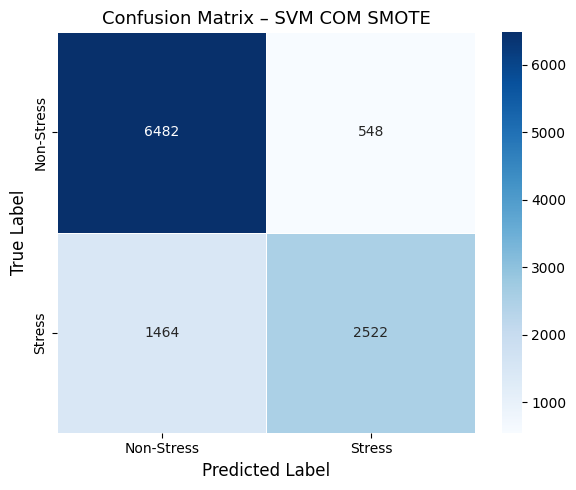

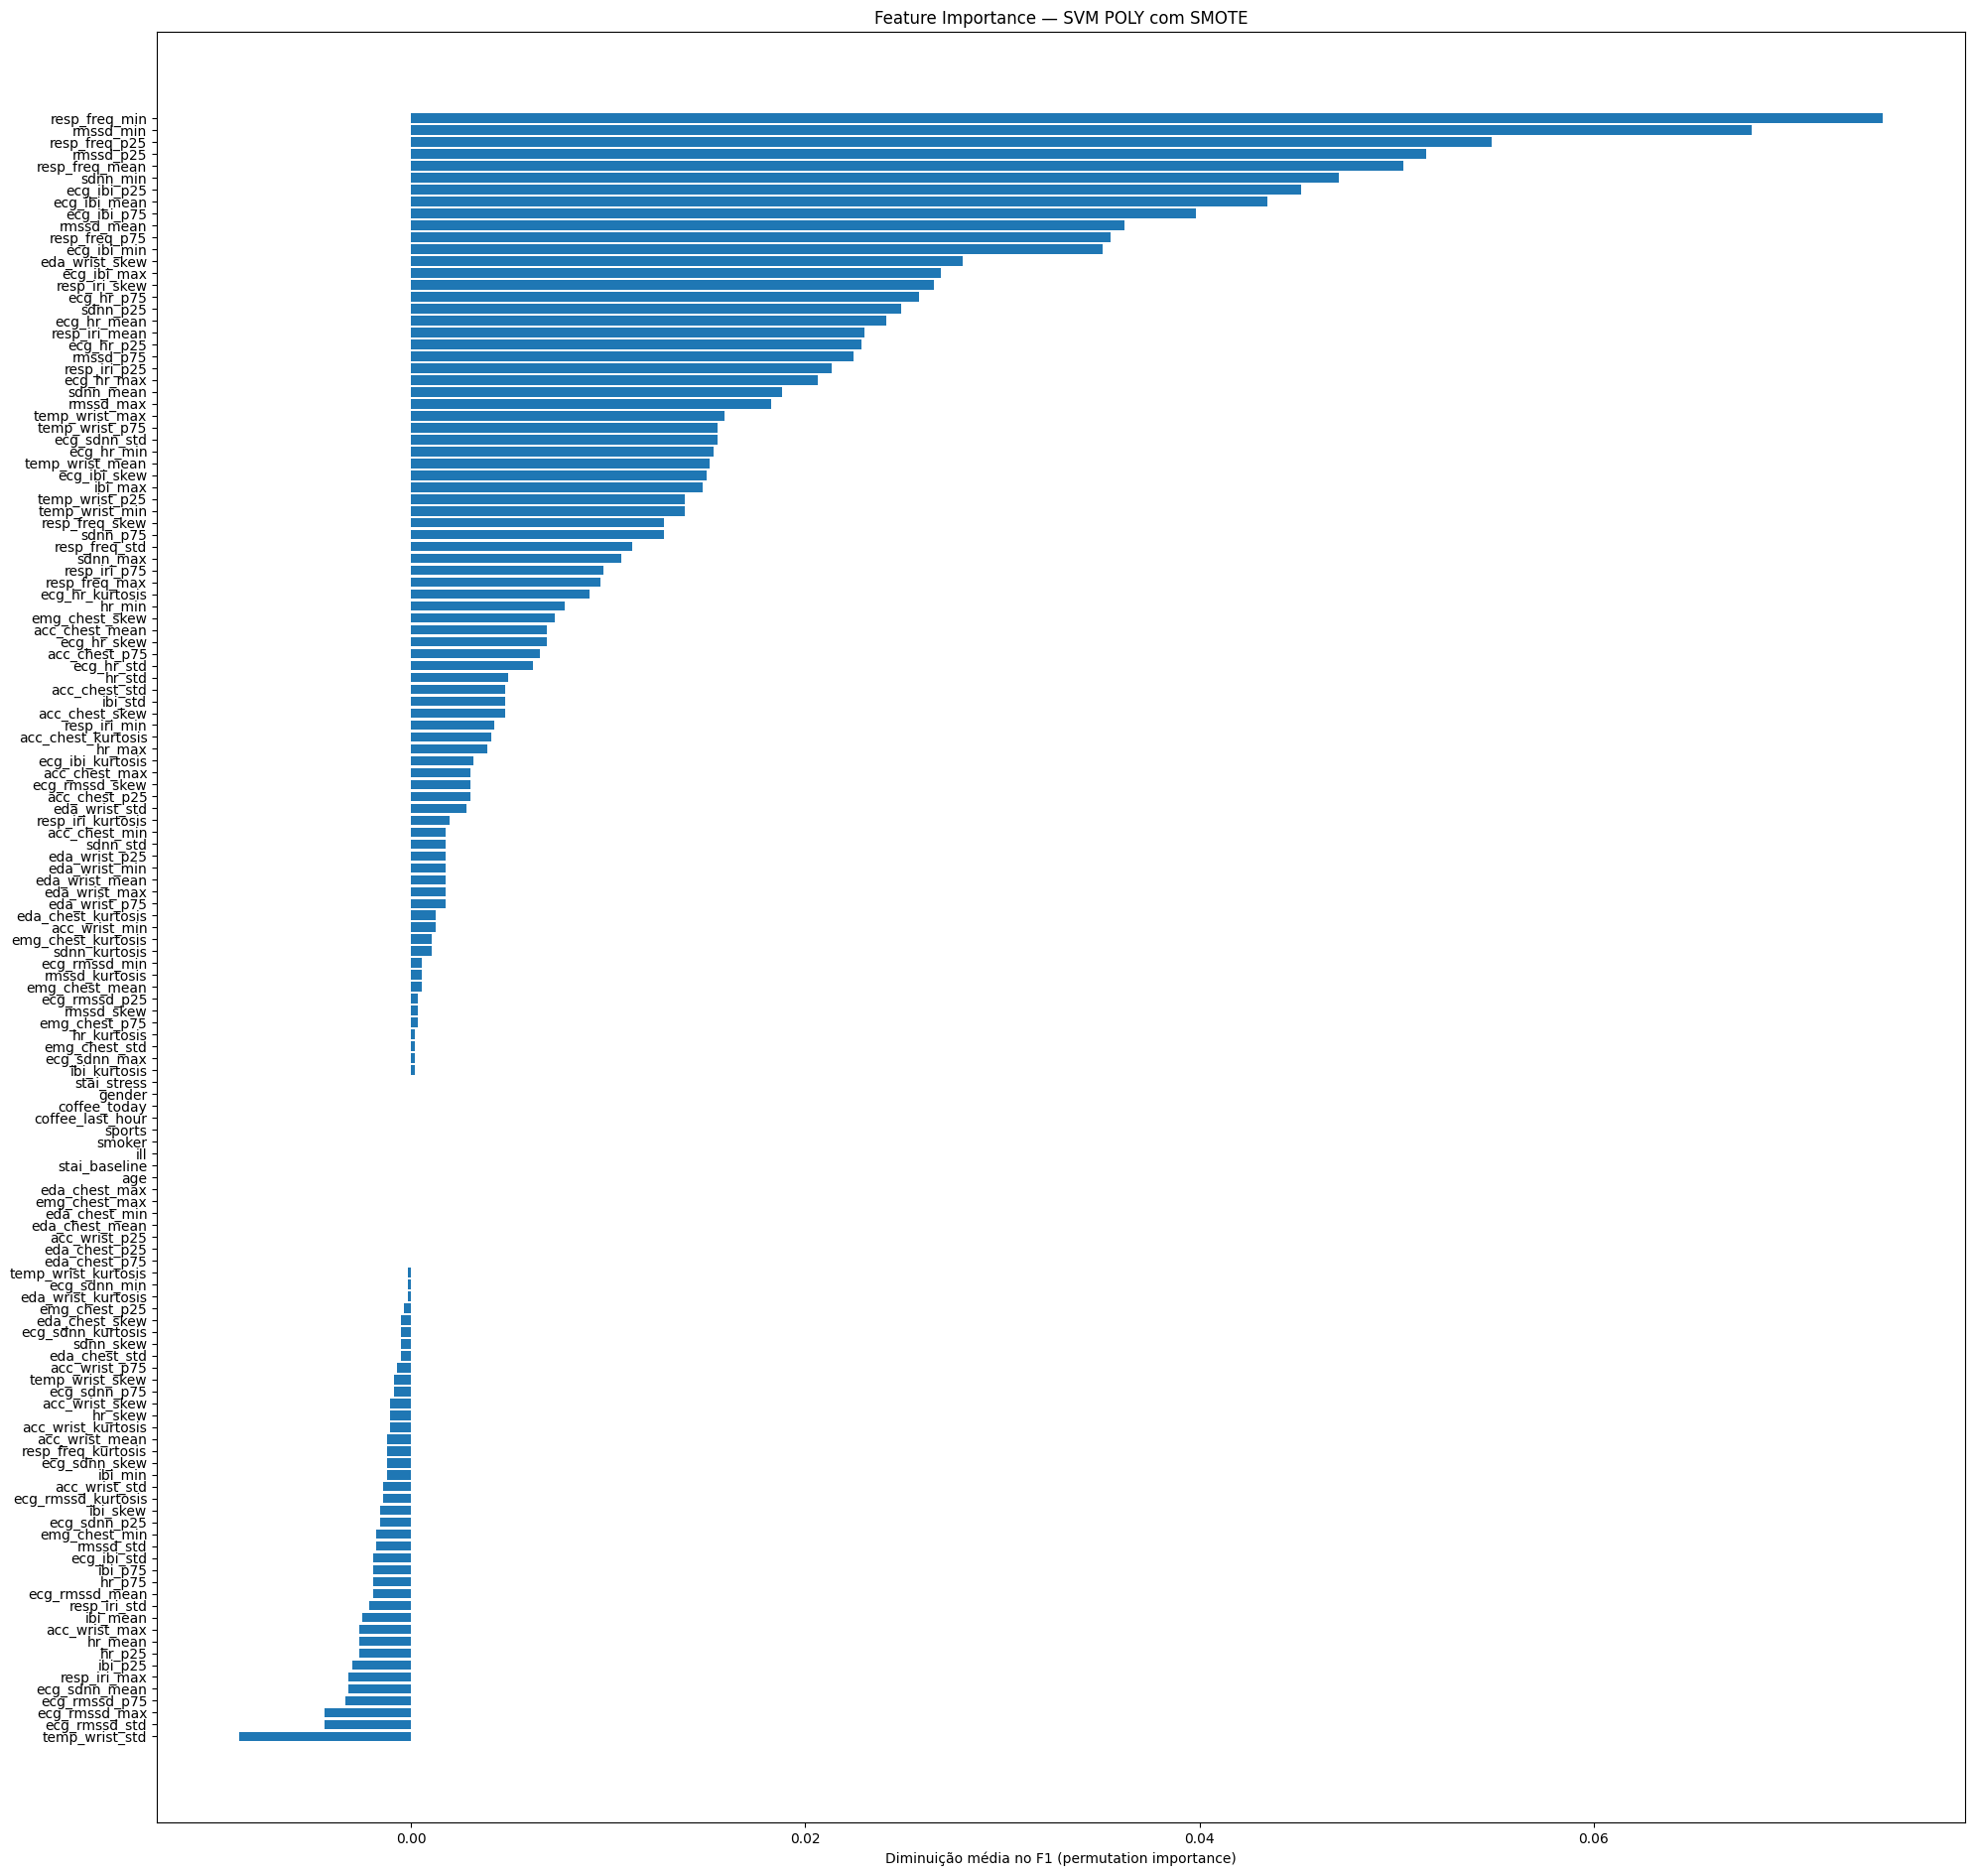


Top 10:
    C kernel gamma class_weight       F1  Accuracy   Recall  ROC-AUC  Bal_Acc      MCC  degree
  0.1   poly  auto     balanced 0.790965  0.816415 0.816415 0.927952 0.773603 0.592852     3.0
  0.1   poly scale     balanced 0.790202  0.815692 0.815692 0.930836 0.772719 0.590986     3.0
  0.1    rbf  auto     balanced 0.764292  0.783600 0.783600 0.896679 0.767135 0.577483     NaN
  0.1    rbf scale     balanced 0.763949  0.783330 0.783330 0.896782 0.766923 0.577081     NaN
  1.0   poly scale     balanced 0.761410  0.778105 0.778105 0.910059 0.775530 0.579855     3.0
  1.0   poly  auto     balanced 0.760236  0.777124 0.777124 0.909795 0.774504 0.577868     3.0
  1.0    rbf scale     balanced 0.757190  0.781472 0.781472 0.900702 0.767329 0.574167     NaN
  1.0    rbf  auto     balanced 0.757177  0.781467 0.781467 0.900607 0.767269 0.574146     NaN
100.0    rbf scale     balanced 0.754241  0.779503 0.779503 0.898777 0.766433 0.572715     NaN
 10.0    rbf scale     balanced 0.754241 

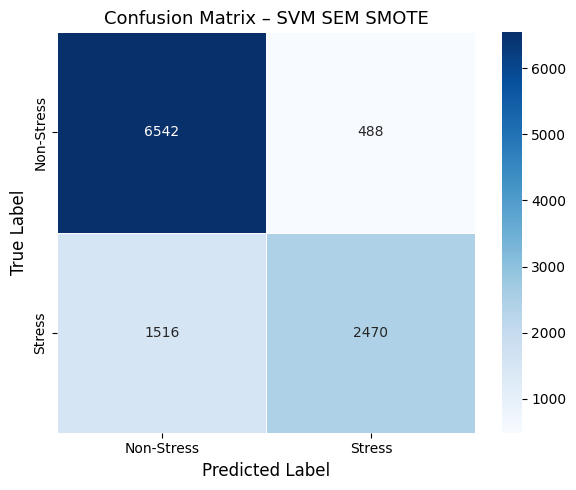

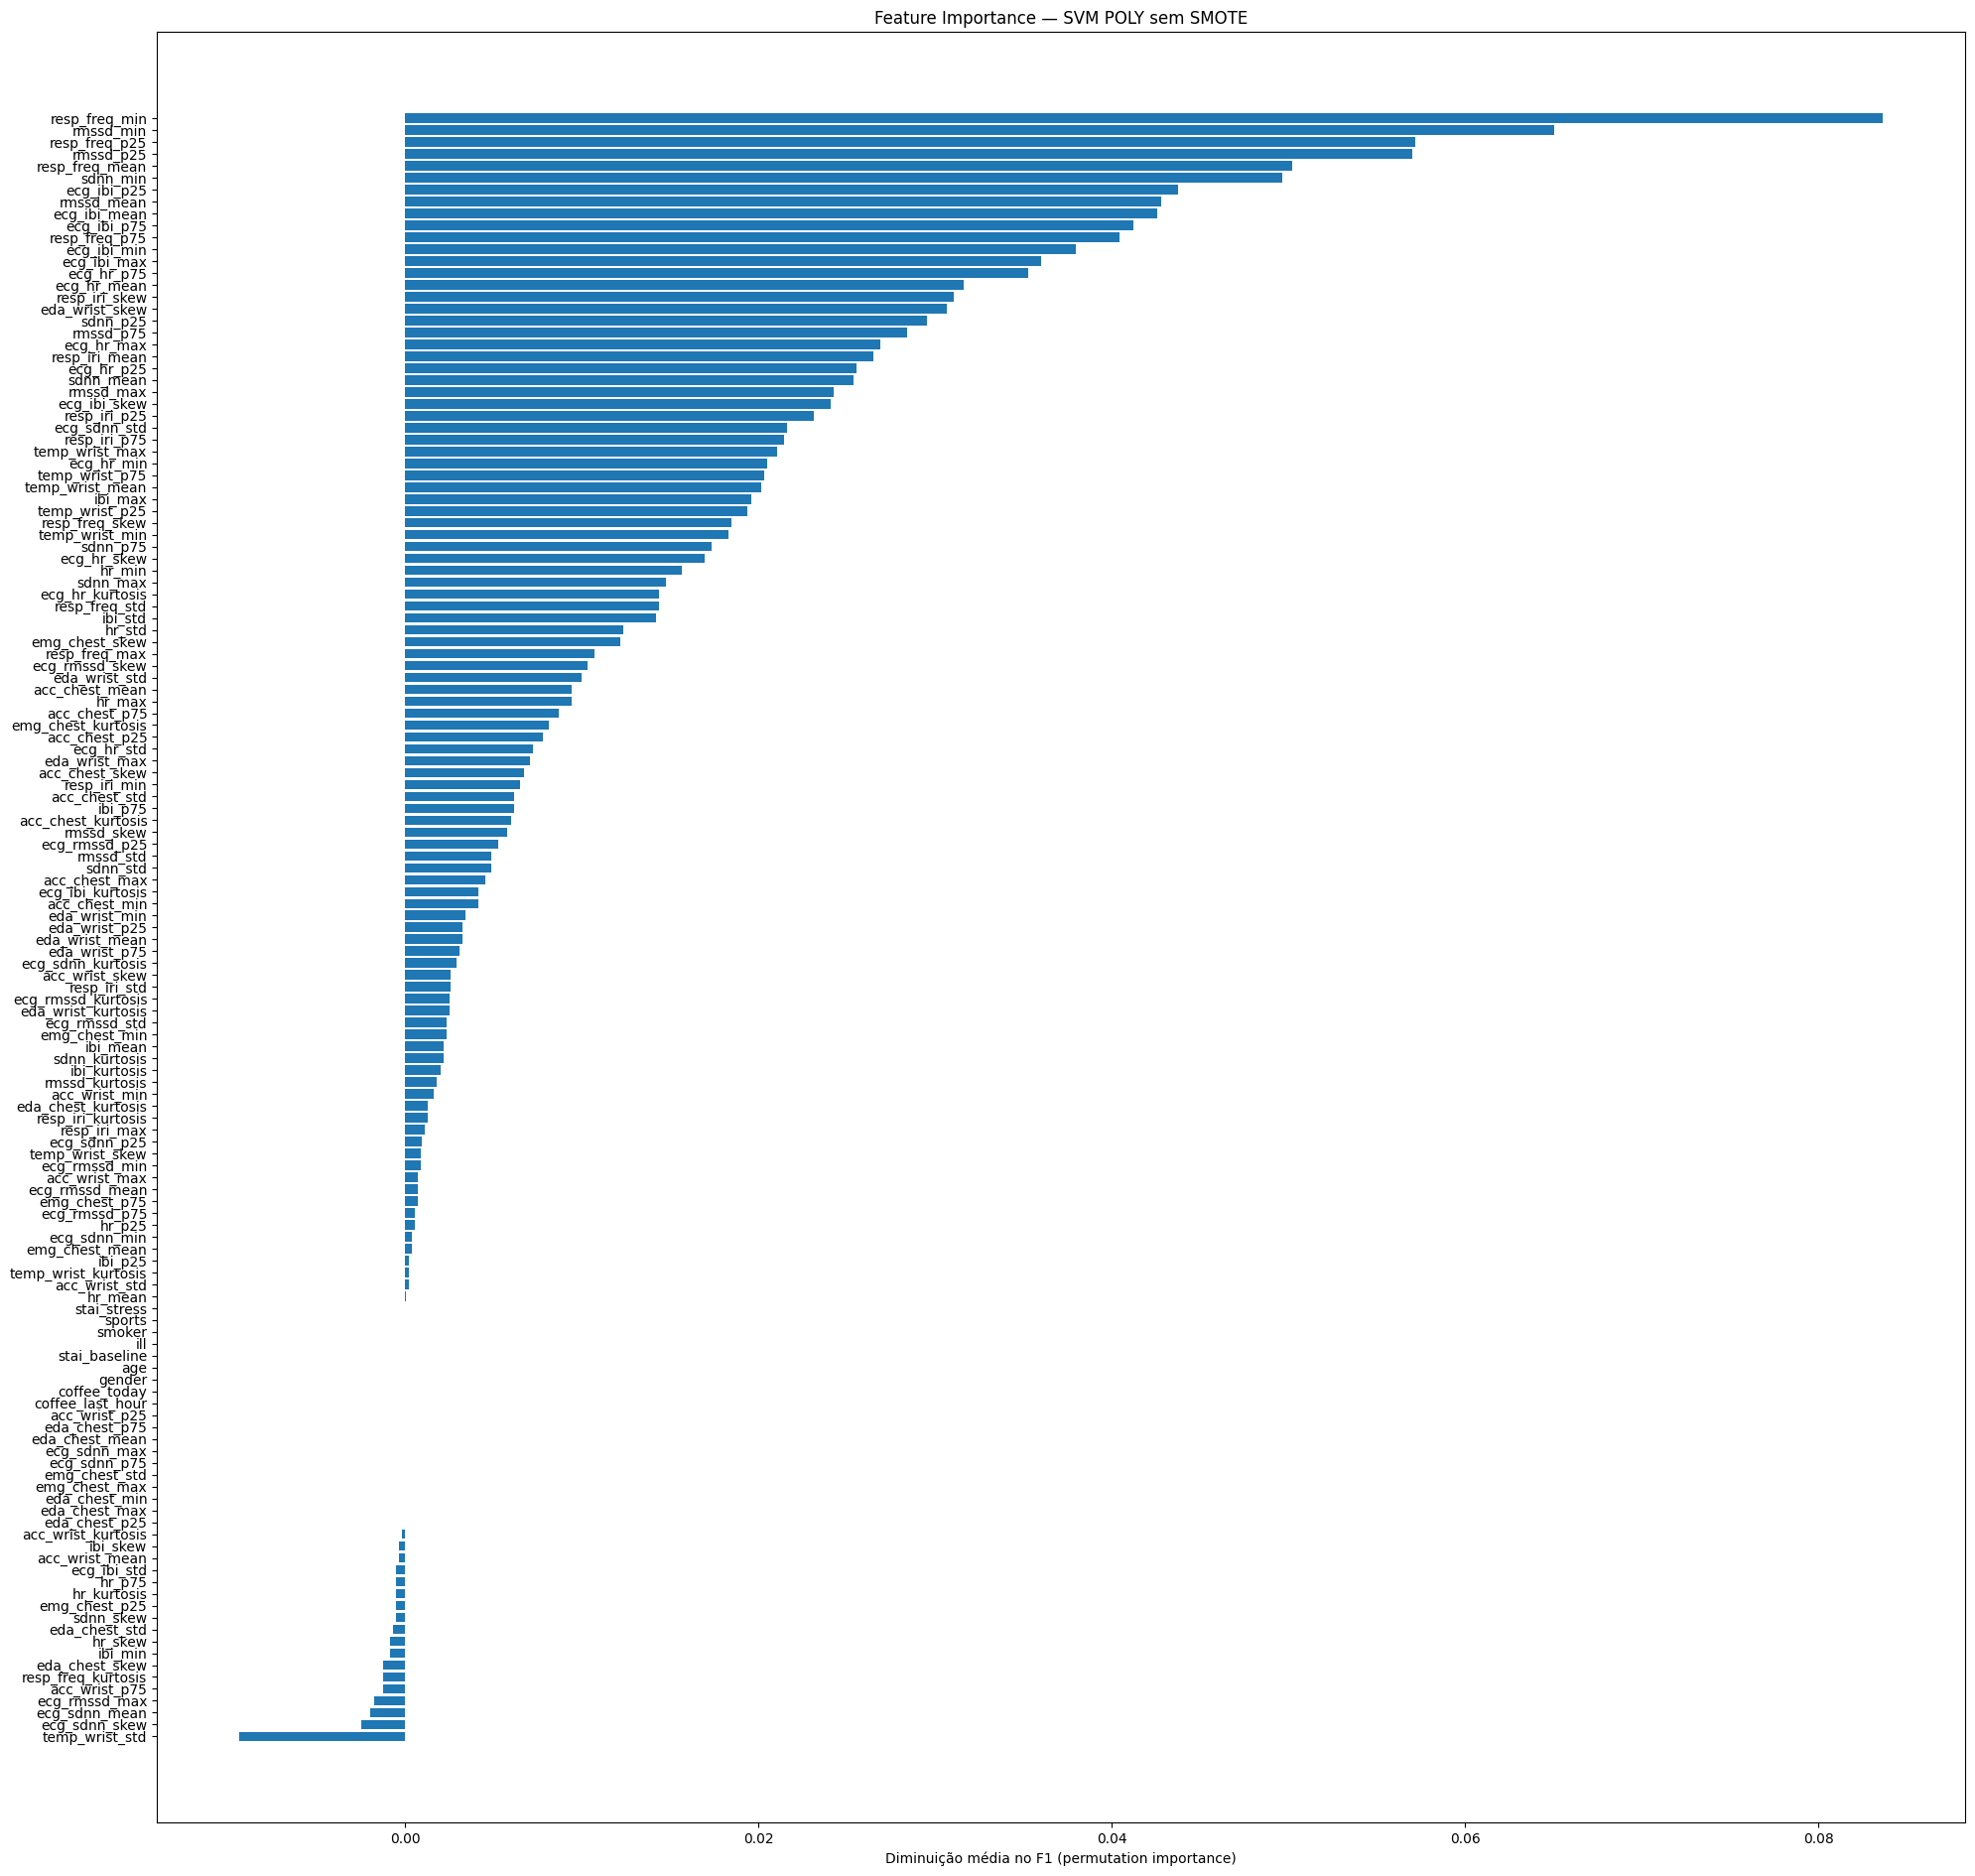


Top 10:
    C kernel gamma class_weight       F1  Accuracy   Recall  ROC-AUC  Bal_Acc      MCC  degree
  0.1   poly scale     balanced 0.790637  0.817204 0.817204 0.930997 0.771461 0.595511     3.0
  0.1   poly  auto     balanced 0.790256  0.816939 0.816939 0.931108 0.770987 0.594895     3.0
  0.1    rbf  auto     balanced 0.766518  0.785933 0.785933 0.897483 0.771412 0.584729     NaN
  0.1    rbf scale     balanced 0.766374  0.785749 0.785749 0.897281 0.771154 0.584337     NaN
  1.0   poly  auto     balanced 0.765357  0.782167 0.782167 0.911797 0.775739 0.581912     3.0
  1.0   poly scale     balanced 0.764883  0.781523 0.781523 0.911627 0.775793 0.581658     3.0
  1.0    rbf scale     balanced 0.757212  0.781386 0.781386 0.900437 0.767215 0.573911     NaN
  1.0    rbf  auto     balanced 0.756736  0.781022 0.781022 0.900568 0.766875 0.573291     NaN
100.0    rbf scale     balanced 0.754449  0.779598 0.779598 0.898513 0.766223 0.571795     NaN
 10.0    rbf scale     balanced 0.754449 

In [5]:
print(f"Total combinações: {len(all_params)} | Folds: {len(folds)}")

for use_smote in [True, False]:
    label = "COM SMOTE" if use_smote else "SEM SMOTE"
    print(f"\n{'='*50}\nA correr {label}...\n{'='*50}")

    all_results = Parallel(n_jobs=-1, prefer='processes')(
        delayed(run_combo)(params, use_smote=use_smote) for params in all_params
    )

    best = max(all_results, key=lambda x: x['f1'])

    print(f"\n{'='*50}")
    print(f"AVALIAÇÃO FINAL — SVM {label}")
    print(f"{'='*50}")
    print(classification_report(best['y_test'], best['y_pred']))
    print(f"ROC-AUC:            {best['roc_auc']:.3f}")
    print(f"Balanced Accuracy:  {best['bal_acc']:.3f}")
    print(f"MCC:                {best['mcc']:.3f}")
    print(f"F1 Std (por fold):  {best['f1_std']:.3f}")
    print(f"Melhores params:    {best['params']}")

    # Confusion Matrix 
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        best['cm'], annot=True, fmt='d', cmap='Blues',
        xticklabels=['Non-Stress', 'Stress'],
        yticklabels=['Non-Stress', 'Stress'],
        linewidths=0.5, ax=ax
    )
    ax.set_xlabel('Predicted Label', fontsize=12)
    ax.set_ylabel('True Label', fontsize=12)
    ax.set_title(f'Confusion Matrix – SVM {label}', fontsize=13)
    plt.tight_layout()
    plt.show()

    # Graph Features — re-treinar no fold mais representativo
    best_params_clean = best['params']
    fold_f1s = []
    for train_idx, test_idx in folds:
        X_tr, X_te = X_svm[train_idx], X_svm[test_idx]
        y_tr, y_te = y_svm[train_idx], y_svm[test_idx]
        imputer = SimpleImputer(strategy='median')
        scaler  = StandardScaler()
        X_tr = imputer.fit_transform(scaler.fit_transform(X_tr))
        X_te = imputer.transform(scaler.transform(X_te))
        if use_smote:
            X_tr, y_tr = SMOTE(random_state=42).fit_resample(X_tr, y_tr)
        model = SVC(**best_params_clean, cache_size=500)
        model.fit(X_tr, y_tr)
        y_pred_fold = model.predict(X_te)
        fold_f1s.append(f1_score(y_te, y_pred_fold, average='weighted', zero_division=0))

    best_fold_idx = np.argmin(np.abs(np.array(fold_f1s) - np.mean(fold_f1s)))
    train_idx, test_idx = folds[best_fold_idx]
    X_tr, X_te = X_svm[train_idx], X_svm[test_idx]
    y_tr, y_te = y_svm[train_idx], y_svm[test_idx]
    
    imputer = SimpleImputer(strategy='median')
    scaler  = StandardScaler()
    X_tr = imputer.fit_transform(scaler.fit_transform(X_tr))
    X_te = imputer.transform(scaler.transform(X_te))
    
    if use_smote:
        X_tr, y_tr = SMOTE(random_state=42).fit_resample(X_tr, y_tr)
        
    model = SVC(**best_params_clean, cache_size=500)
    model.fit(X_tr, y_tr)

    perm = permutation_importance(
        model, X_te, y_te,
        n_repeats=10, random_state=42,
        scoring='f1_weighted', n_jobs=-1
    )
    indices = np.argsort(perm.importances_mean)
    
    plt.figure(figsize=(20, 19))
    plt.barh(np.array(feature_cols)[indices], perm.importances_mean[indices])
    plt.xlabel("Diminuição média no F1 (permutation importance)")
    plt.title(f"Feature Importance — SVM {best_params_clean['kernel'].upper()} {'com' if use_smote else 'sem'} SMOTE")
    plt.tight_layout()
    plt.show()

    df_res = pd.DataFrame([
        {**r['params'], 'F1': r['f1'], 'Accuracy': r['accuracy'],
         'Recall': r['recall'], 'ROC-AUC': r['roc_auc'],
         'Bal_Acc': r['bal_acc'], 'MCC': r['mcc']}
        for r in all_results
    ]).sort_values('F1', ascending=False)
    print("\nTop 10:")
    print(df_res.head(10).to_string(index=False))

    # curvas ROC
    smote_tag = 'smote' if use_smote else 'no_smote'
    os.makedirs('/kaggle/working/roc_data', exist_ok=True)

    roc_data_svm = {
        'y_test':      best['y_test'],
        'y_pred':      best['y_pred'],
        'y_prob':      best['y_prob'],
        'roc_auc':     roc_auc_score(best['y_test'], best['y_prob']),
        'model':       'SVM',
        'smote':       use_smote,
        'f1':          best['f1'],
        'f1_std':      best['f1_std'],
        'accuracy':    best['accuracy'],
        'recall':      best['recall'],
        'bal_acc':     best['bal_acc'],
        'mcc':         best['mcc'],
        'cm':          best['cm'],
        'best_params': best['params'],
    }

    fname = f'/kaggle/working/roc_data/svm_{smote_tag}.pkl'
    with open(fname, 'wb') as f:
        pickle.dump(roc_data_svm, f)
    print(f"\nGuardado em: {fname}")